In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Part 1: Data Import & Understanding

In [2]:
# -----------------------------
#       Import the Dataset
# -----------------------------
df = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
# -----Display first 5 rows-----
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# -----Display last 5 rows-----
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
# -----Check dataset shape-----
df.shape

(7043, 21)

In [6]:
# -----Display column names-----
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
# -----Check data types-----
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
# -----Identifying Numerical & Categorical columns-----
print("Numerical:", df.select_dtypes(include = "number").columns.tolist())
print("Categorical:", df.select_dtypes(exclude = "number").columns.tolist())

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [9]:
# -----Basic Statistical Information-----
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


**What I noticed:** 7,043 customers and 21 columns. `TotalCharges` is stored as text (it should be a number) and `SeniorCitizen` is 0/1 instead of No/Yes.

# Part 2: Data Cleaning

In [10]:
# -----Check missing values-----
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
# -----Check Total Charges
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors = "coerce")
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
# -----Handle missing values-----
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [13]:
# -----Check & Remove duplicate records-----
print("Duplicate rows before removal:", df.duplicated().sum())
print("Duplicate customer IDs before removal:", df["customerID"].duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after removal:", df.duplicated().sum())
print("Duplicate customer IDs after removal:", df["customerID"].duplicated().sum())

Duplicate rows before removal: 0
Duplicate customer IDs before removal: 0
Duplicate rows after removal: 0
Duplicate customer IDs after removal: 0


In [14]:
# -----Identify incorrect data types-----
print("---Data types after cleaning---\n")
print(df.dtypes)

print("\nTotalCharges data type:", df["TotalCharges"].dtype)
print("tenure data type:", df["tenure"].dtype)
print("MonthlyCharges data type:", df["MonthlyCharges"].dtype)

---Data types after cleaning---

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

TotalCharges data type: float64
tenure data type: int64
MonthlyCharges data type: float64


**Cleaning decisions**

- `TotalCharges` was stored as text, so I converted it to numeric format using `pd.to_numeric()`.

- After conversion, 11 missing values were created because these customers had blank `TotalCharges` 
values. These customers have a tenure of 0 months, so they have not generated any charges yet. Therefore, the missing values were filled with 0.

- `SeniorCitizen` is represented as 0 and 1 in the original dataset. I kept this numeric representation because it is suitable for statistical and correlation analysis.

- `No internet service` and `No phone service` were kept as separate categories because they provide information about the customer's service status.

- `Churn` was converted into a numerical variable (`Churn_num`) where Yes = 1 and No = 0 for correlation analysis.

- Duplicate rows and duplicate customer IDs were checked. No duplicates were found.

- No records were removed based on outliers because the identified values were within reasonable ranges for this customer dataset.

In [15]:
# -----Check invalid or inconsistent values-----
print("Tenure range:", df["tenure"].min(), "to", df["tenure"].max())
print("Monthly Charges range:", df["MonthlyCharges"].min(), "to", df["MonthlyCharges"].max())
print("Total Charges range:", df["TotalCharges"].min(), "to", df["TotalCharges"].max())

print("\n-----Churn categories-----")
print(df["Churn"].unique())

print("\nInvalid tenure values:", (df["tenure"] < 0).sum())
print("Invalid monthly charges:", (df["MonthlyCharges"] < 0).sum())
print("Invalid total charges:", (df["TotalCharges"] < 0).sum())

print("\nUnique values in SeniorCitizen:", df["SeniorCitizen"].unique())     

Tenure range: 0 to 72
Monthly Charges range: 18.25 to 118.75
Total Charges range: 0.0 to 8684.8

-----Churn categories-----
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Invalid tenure values: 0
Invalid monthly charges: 0
Invalid total charges: 0

Unique values in SeniorCitizen: [0 1]


In [16]:
# -----Verifying the dataset-----
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\n\n    -----Data types-----\n")
print(df.dtypes)

Dataset shape: (7043, 21)
Total missing values: 0
Total duplicate rows: 0
Duplicate customer IDs: 0


    -----Data types-----

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


# Part 3: Feature Analysis

In [17]:
# -----Numerical Features-----
numerical_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_columns].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [18]:
# -----Categorical Features-----
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

categorical_columns

C:\Users\User\AppData\Local\Temp\ipykernel_6864\2774830779.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

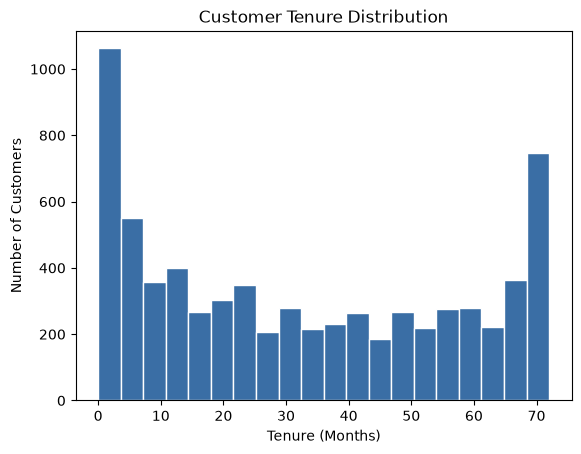

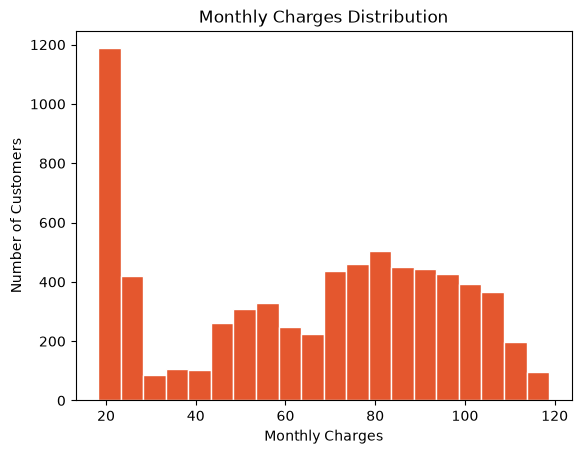

In [19]:
# -----Feature Distributions-----

# -----Tenure Distribution-----
plt.hist(df["tenure"], bins = 20, color = "#3A6EA5", edgecolor = "white")
plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

# -----Monthly Charges Distribution-----
plt.hist(df["MonthlyCharges"], bins = 20, color = "#E4572E", edgecolor = "white")
plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

In [20]:
# -----Minimum & Maximum values-----
print("---Minimum values---\n", df[numerical_columns].min())
print("\n---Maximum values---\n", df[numerical_columns].max())

---Minimum values---
 SeniorCitizen      0.00
tenure             0.00
MonthlyCharges    18.25
TotalCharges       0.00
dtype: float64

---Maximum values---
 SeniorCitizen        1.00
tenure              72.00
MonthlyCharges     118.75
TotalCharges      8684.80
dtype: float64


In [21]:
# -----Average values-----
df[numerical_columns].mean()

SeniorCitizen        0.162147
tenure              32.371149
MonthlyCharges      64.761692
TotalCharges      2279.734304
dtype: float64

In [22]:
# -----Important categories-----
print(df["Contract"].value_counts())
print(df["InternetService"].value_counts())
print(df["PaymentMethod"].value_counts())
print(df["Churn"].value_counts())

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [23]:
# -----Outliers (if any)----
for col in numerical_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    print(col, 'Outliers:', count)

SeniorCitizen Outliers: 1142
tenure Outliers: 0
MonthlyCharges Outliers: 0
TotalCharges Outliers: 0


The IQR method was used to identify potential statistical outliers. `SeniorCitizen` is flagged (1,142 customers), but it is only a 0/1 flag, so those are simply the senior customers and not real outliers. `tenure`, `MonthlyCharges` and `TotalCharges` have no outliers. No observations were removed because of outlier status.

**Important features for customer churn**

Based on the exploratory analysis, contract type, tenure, internet service, payment method, online security, and technical support appear to be important features associated with customer churn.

Gender and phone service appear to have weaker differences in churn compared with these features.

These observations are based on the differences visible in the categorical analysis and visualizations. They describe associations in the dataset and do not imply that these features directly cause churn.

# Part 4: Correlation Analysis

In [24]:
# -----Convert churn to numeric-----
df["Churn_num"] = df["Churn"].map({"Yes": 1, "No": 0})
print(df["Churn_num"].value_counts())

Churn_num
0    5174
1    1869
Name: count, dtype: int64


In [25]:
# -----Correlation Matrix & Heatmap-----
correlation = df[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Churn_num"
    ]
].corr()

correlation

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_num
SeniorCitizen,1.000000,0.016567,0.220173,0.103006,0.150889
tenure,0.016567,1.000000,0.247900,0.826178,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651174,0.193356
TotalCharges,0.103006,0.826178,0.651174,1.000000,-0.198324
Churn_num,0.150889,-0.352229,0.193356,-0.198324,1.000000


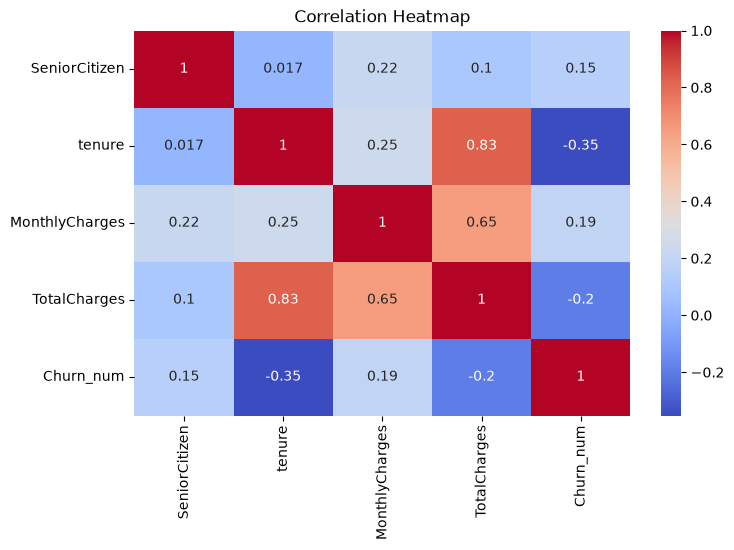

In [26]:
# -----Correlation Heatmap-----

plt.figure(figsize = (8, 5))
sns.heatmap(correlation, annot=True, cmap = "coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Correlation Findings

- **Strong positive relationship:** `tenure` and `TotalCharges` show a strong positive relationship (approximately 0.83). Customers with longer tenure generally accumulate higher total charges.

- **Strong positive relationship:** `MonthlyCharges` and `TotalCharges` also show a positive relationship (approximately 0.65).

- **Strongest negative relationship with churn:** `tenure` and `Churn_num` show a negative relationship (approximately -0.35), indicating that customers with longer tenure generally have lower churn.

- **Weak positive relationship:** `MonthlyCharges` and `Churn_num` show a relatively weak positive relationship (approximately 0.19).

- `TotalCharges` is strongly related to tenure because total charges accumulate over the customer's period with the company. Therefore, the correlation between `TotalCharges` and churn should not be interpreted as an independent causal relationship.

In [27]:
# -----Important Feature relationships-----
df["TenureGroup"] = pd.cut(df["tenure"], bins = [-1, 12, 24, 48, 60, 72],
                        labels = ["0-12", "13-24", "25-48", "49-60", "61-72"])
(df.groupby("TenureGroup", observed = True)["Churn_num"].mean() * 100).round(1)

TenureGroup
0-12     47.4
13-24    28.7
25-48    20.4
49-60    14.4
61-72     6.6
Name: Churn_num, dtype: float64

Tenure and churn (-0.35) is the strongest link with churn, and churn falls from 47.4% in months 0–12 to 6.6% after 5 years. MonthlyCharges and churn (+0.19) is weak. TotalCharges is mostly tenure × monthly charges, so it is not a separate cause.

# Part 5: Data Visualizations

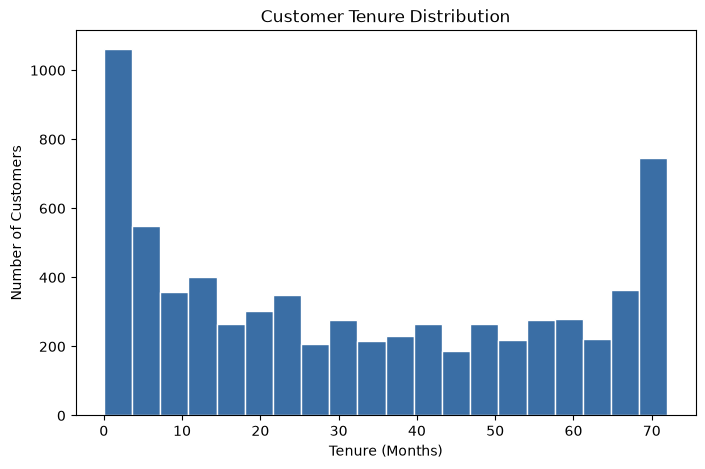

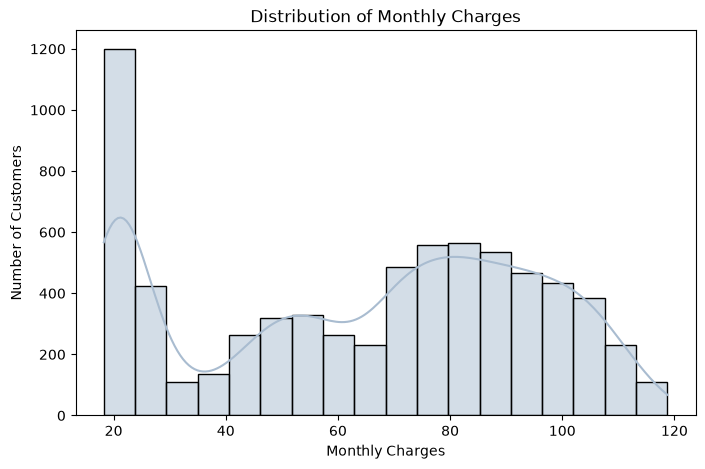

In [28]:
# -----Histogram-----
plt.figure(figsize = (8, 5))
plt.hist(df["tenure"], bins = 20, color = "#3A6EA5", edgecolor = "white")
plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show() 

plt.figure(figsize = (8, 5))
sns.histplot(data = df, x = "MonthlyCharges", color = "#A9BCD0", kde = True)
plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

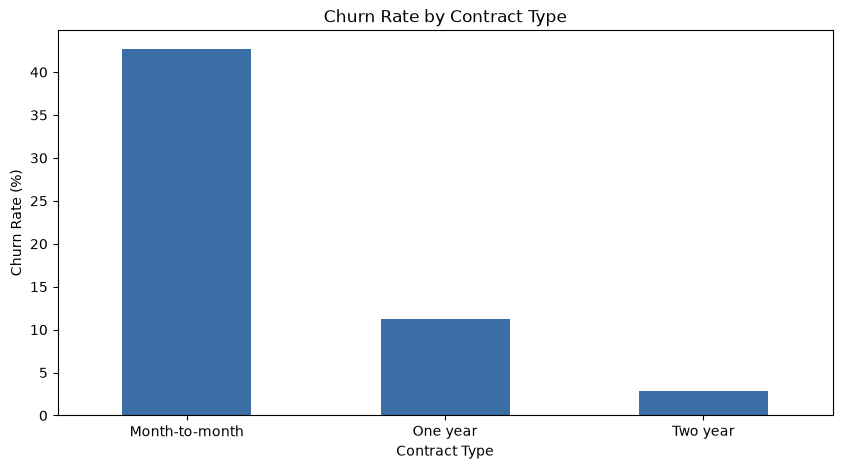

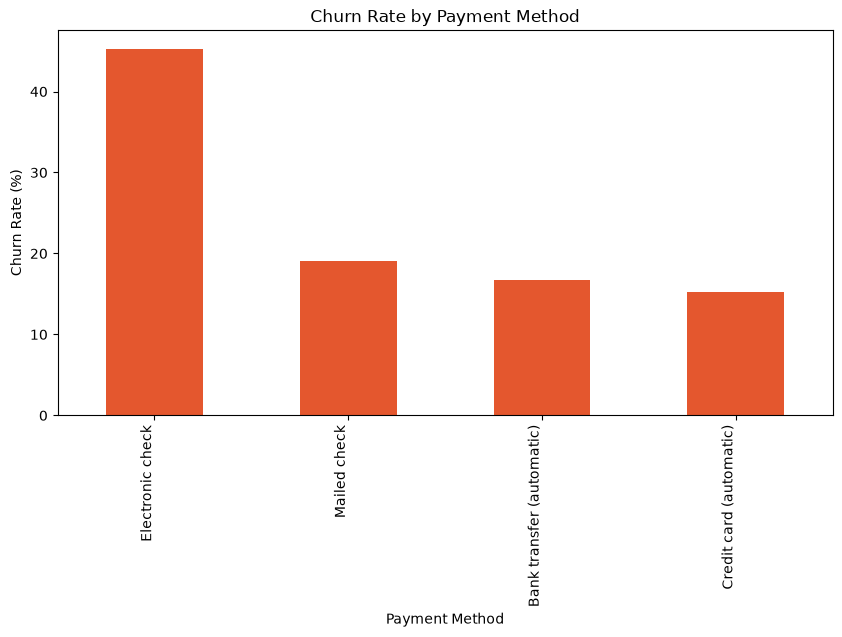

In [29]:
# -----Bar Chart-----
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize = "index") * 100
contract_churn["Yes"].plot(kind = "bar", figsize = (10, 5), color = "#3A6EA5")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation = 0)
plt.show()


payment_churn = pd.crosstab(df["PaymentMethod"],df["Churn"], normalize = "index") * 100
payment_churn["Yes"].sort_values(ascending = False).plot(kind = "bar", color = "#E4572E", figsize = (10, 5))
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation = 90, ha = "right")
plt.show()

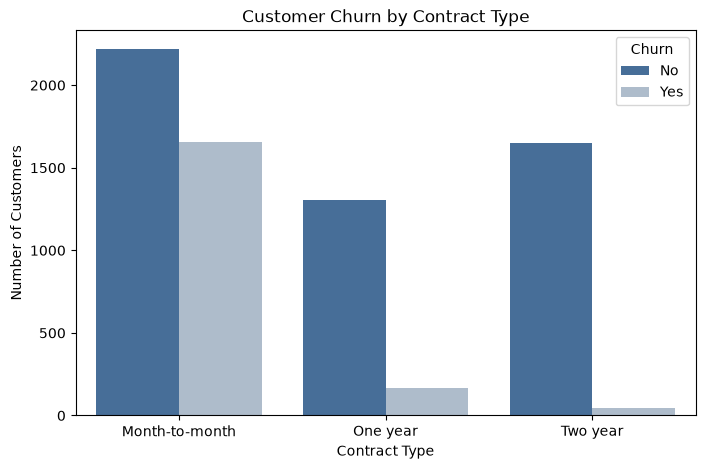

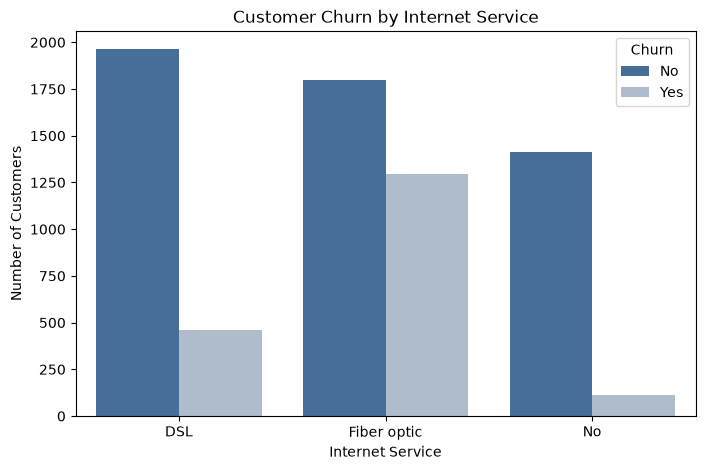

In [30]:
# -----Count Plot-----
plt.figure(figsize = (8, 5))
sns.countplot(data = df, x = "Contract", hue = "Churn", palette = ["#3A6EA5", "#A9BCD0"])
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

plt.figure(figsize = (8, 5))
sns.countplot(data = df, x = "InternetService", hue = "Churn", palette = ["#3A6EA5", "#A9BCD0"])
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

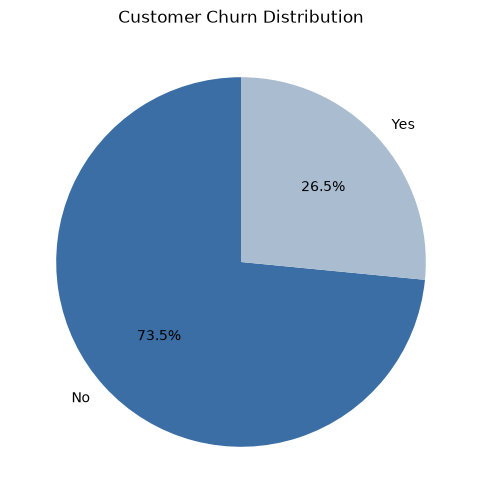

In [31]:
# -----Pie Chart-----
churn_counts = df["Churn"].value_counts()
plt.figure(figsize = (6, 6))
plt.pie(churn_counts, labels = churn_counts.index, autopct = "%1.1f%%", startangle = 90, colors = ["#3A6EA5", "#A9BCD0"])
plt.title("Customer Churn Distribution")
plt.show()

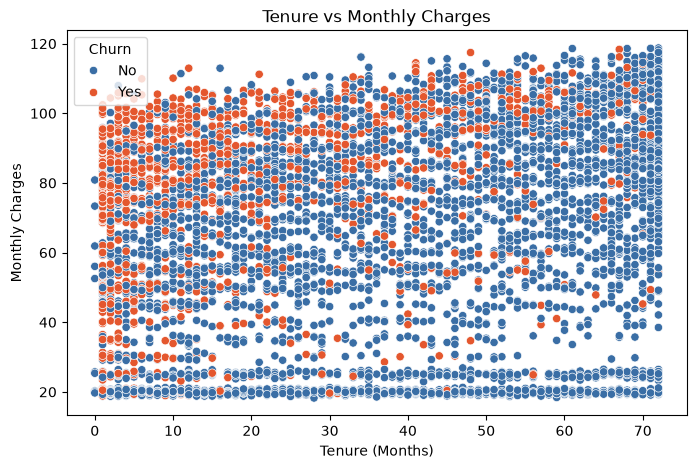

In [32]:
# -----Scatter Plot-----
plt.figure(figsize = (8, 5))
sns.scatterplot(data = df, x = "tenure", y = "MonthlyCharges", hue = "Churn", palette = ["#3A6EA5", "#E4572E"])
plt.title("Tenure vs Monthly Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.show()

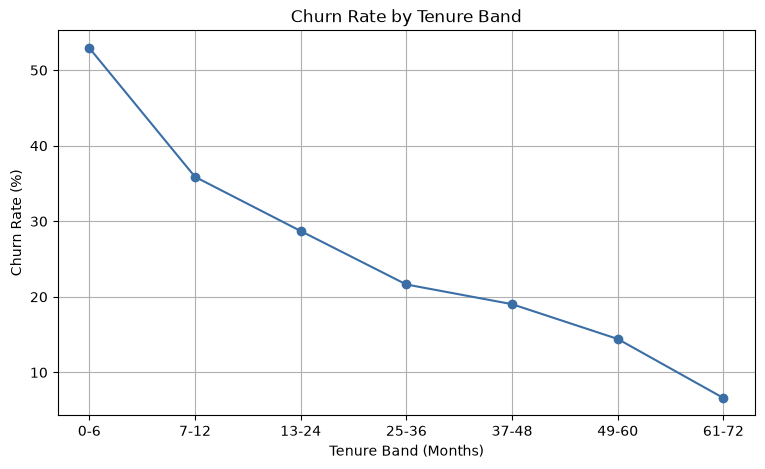

In [33]:
# -----Line Chart-----
df["TenureBand"] = pd.cut(df["tenure"],
    bins = [-1, 6, 12, 24, 36, 48, 60, 72],
    labels = [
        "0-6",
        "7-12",
        "13-24",
        "25-36",
        "37-48",
        "49-60",
        "61-72"
    ])
tenure_churn = pd.crosstab(df["TenureBand"], df["Churn"], normalize = "index") * 100
plt.figure(figsize = (9, 5))
plt.plot(tenure_churn.index.astype(str), tenure_churn["Yes"], marker = "o", color = "#3A6EA5")
plt.title("Churn Rate by Tenure Band")
plt.xlabel("Tenure Band (Months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation = 0)
plt.grid(True)
plt.show()

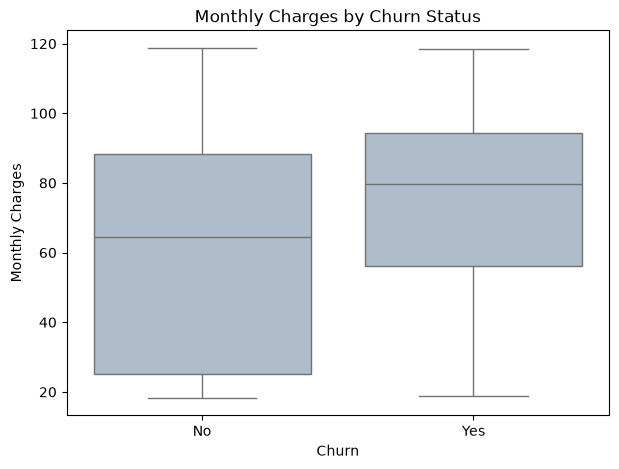

In [34]:
# -----Box Plot-----
plt.figure(figsize = (7, 5))
sns.boxplot(data = df,x = "Churn", y = "MonthlyCharges", color = "#A9BCD0")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

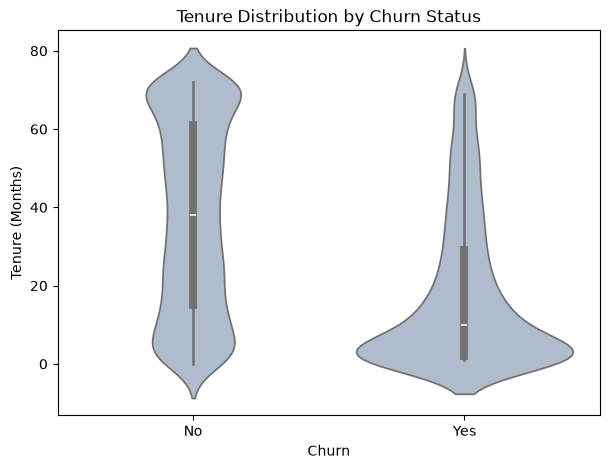

In [35]:
# -----Violin Plot-----
plt.figure(figsize = (7, 5))
sns.violinplot(data = df, x = "Churn", y = "tenure", color = "#A9BCD0")
plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

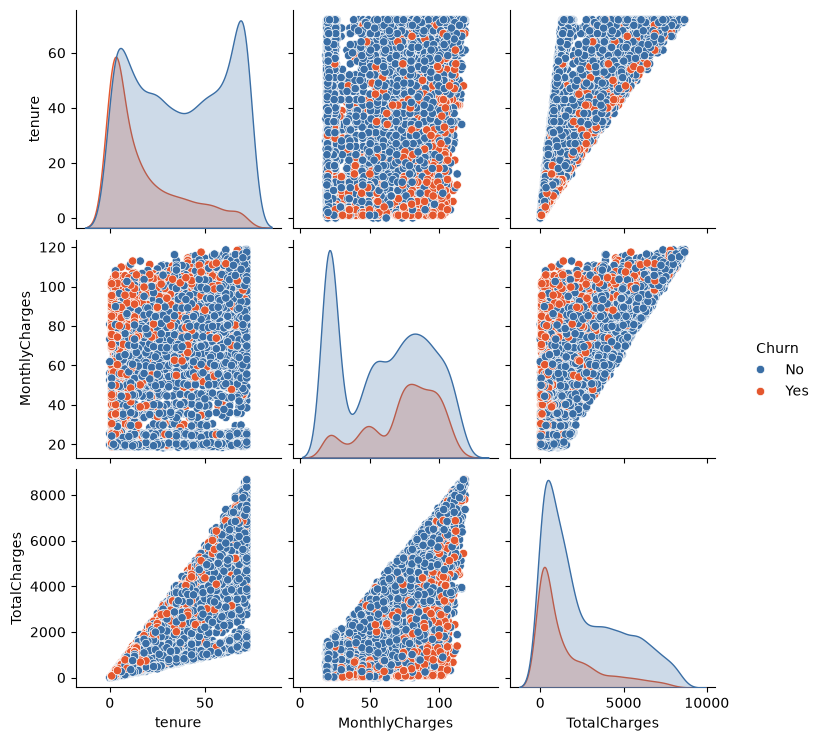

In [36]:
# -----Pair Plot-----
sns.pairplot(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]], hue = "Churn", palette = ["#3A6EA5", "#E4572E"])
plt.show()

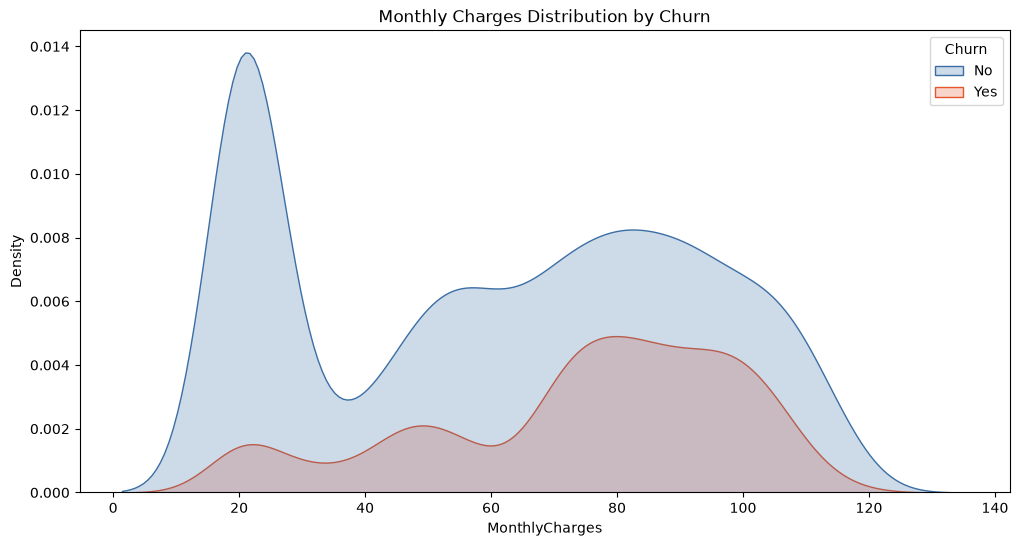

In [37]:
# -----Distribution Plot-----
plt.figure(figsize = (12, 6))
sns.kdeplot(data = df, x = 'MonthlyCharges', hue = 'Churn', fill = True, palette = ["#3A6EA5", "#E4572E"])
plt.title('Monthly Charges Distribution by Churn')
plt.show()

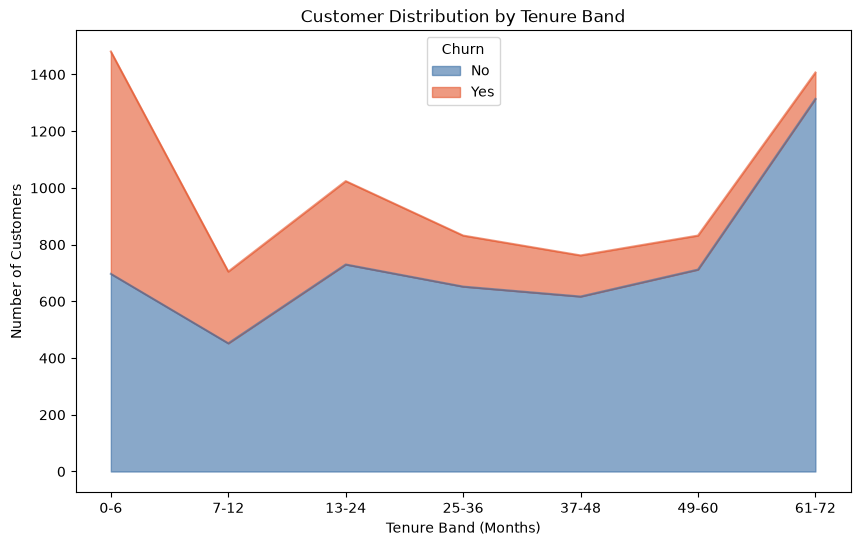

In [38]:
# -----Area Chart-----
tenure_counts = pd.crosstab(df["TenureBand"], df["Churn"])
tenure_counts.plot(kind = "area", figsize = (10, 6), alpha = 0.6, color = ["#3A6EA5", "#E4572E"])
plt.title("Customer Distribution by Tenure Band")
plt.xlabel("Tenure Band (Months)")
plt.ylabel("Number of Customers")
plt.xticks(rotation = 0)
plt.legend(title = "Churn")
plt.show()

# Part 6: Business Insights

1.	Overall churn is high. 1,869 of 7,043 customers (26.5%) have left, roughly one in four.

2.	Contract type is the clearest dividing line. Churn is 42.7% on month-to-month, 11.3% on one-year and only 2.8% on two-year contracts.

3.	Month-to-month customers make up most churners. They are 55% of customers but 88.6% of churners (1,655 of 1,869).

4.	Churn drops steadily with tenure. It falls from 47.4% in months 0–12 to 6.6% after month 60. Churners have a median tenure of 10 months against 38 for stayers, and tenure has the strongest correlation with churn (−0.35).

5.	The first year is the danger zone. Customers in their first 12 months are 31% of the base but 55.5% of all churners (1,037).

6.	Churn takes a large share of revenue. Churned customers paid $139,131 a month, which is 30.5% of all monthly charges ($456,117).

7.	Fiber optic is the highest-churn internet service category. Fiber churn is 41.9% against 19.0% for DSL and 7.4% for no internet, and fiber accounts for 69.4% of all churners.

8.	Fiber customers have higher average monthly charges. Average monthly charge is $91.50 for fiber against $58.10 for DSL, so price against perceived value is worth checking.

9.	Electronic check is a risk signal. 45.3% of electronic check customers churn (1,071 of 2,365), against 15–19% for the other three payment methods.

10.	Paperless billing goes with higher churn. 33.6% churn with paperless billing against 16.3% without, though this overlaps with electronic check use.

11.	Missing protection services goes with churn. Customers without online security churn at 41.8% (14.6% with it) and without tech support at 41.6% (15.2% with it).

12.	Tech support matters most for fiber. Fiber customers without tech support churn at 49.4% against 22.6% with it.

13.	Household ties help retention. Customers without a partner churn at 33.0% (19.7% with one) and without dependents at 31.3% (15.5% with them).

14.	Senior citizens are a high-risk group. They are 16.2% of customers but churn at 41.7% against 23.6% for non-seniors.

15.	Higher bills go with higher churn, but only weakly. Churners pay a mean of $74.44 against $61.27 (median $79.65 vs $64.43). Churn is 10.9% for bills up to $35 and 35.4% above $70, but the correlation is only 0.19. Gender and phone service show almost no effect.




# Part 7: Business Improvement & Recommendations

1.	Move month-to-month customers onto longer contracts. Month-to-month churn is 42.7% against 2.8% on two-year plans, and 1,655 churners came from this group. Offer a small discount or a free add-on for switching to a one- or two-year plan. Average bills are similar across contracts ($66.40 vs $60.77), so a modest incentive is realistic.

2.	Build a first-year retention programme. 47.4% of customers in months 0–12 leave, and about 53% in the first six months. Welcome calls and check-ins at months 1, 3 and 6, plus an early upgrade offer, would reach the 55.5% of churners who go in year one.

3.	Review fiber optic pricing and service quality. Fiber churn is 41.9% with average bills of $91.50, and fiber supplies 69.4% of churners. Survey fiber customers on speed, outages and price, and test a price-matched plan.

4.	Push electronic check customers to automatic payment. They churn at 45.3% against about 15% for card auto-pay, and there are 2,365 of them. Offer a one-time bill credit for switching to bank or card auto-pay.

5.	Bundle online security and tech support for at-risk customers. The 2,553 customers with neither service churn at 49.0%, and fiber customers without tech support churn at 49.4% against 22.6% with it. Include a free trial of both in new fiber and month-to-month plans.


**Priority target:** month-to-month, fiber, electronic check customers. This overlap is 1,307 customers with a 
60.4% churn rate, the best place to start.

# Conclusion

The analysis of 7,043 Telco customers shows that churn is closely tied to contract type and tenure. Month-to-month customers and first-year customers account for most departures. Fiber optic service, electronic check payment, missing security and support services, and higher monthly bills also stand out. Tenure has the strongest relationship with churn among the numerical variables (−0.35).

These findings point to clear retention targets: new customers, month-to-month customers, and fiber customers without support. The results are associations from EDA and not proof of cause so the next step would be a predictive model with feature engineering.
